## TP2 - Situação de Aprendizagem: MULTIDENSE-ENGINE

### 1 - Importando bibliotecas e configurações Pandas

In [11]:
import kagglehub
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import keras
from kagglehub import KaggleDatasetAdapter
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.set_option("display.max_colwidth", None)

### 2 - Trazendo a base do kaggle

In [5]:
file_path = "breast-cancer.csv"

# Load the latest version
df = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "yasserh/breast-cancer-dataset",
  file_path,
  # Provide any additional arguments like 
  # sql_query or pandas_kwargs. See the 
  # documenation for more information:
  # https://github.com/Kaggle/kagglehub/blob/main/README.md#kaggledatasetadapterpandas
)

df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


### 3 - Tratamento dos dados

A coluna de diagnóstico possue as classificações B = Benigno e M = Maligno que se referem ao tipo de nódulo encontrado nos exames registrados

In [6]:
df = df.drop_duplicates().copy()
df["diagnosis"] = df["diagnosis"].map({"M": 1, "B": 0}).astype(int)
df = df.rename(columns={"diagnosis": "diagnosis_target"})
df.head()

,id,diagnosis_target,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [7]:
df.describe()

,id,diagnosis_target,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,3.037183e+07,0.372583,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,0.405172,1.216853,2.866059,40.337079,0.007041,0.025478,0.031894,0.011796,0.020542,0.003795,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,1.250206e+08,0.483918,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,0.277313,0.551648,2.021855,45.491006,0.003003,0.017908,0.030186,0.006170,0.008266,0.002646,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,8.670000e+03,0.000000,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,0.111500,0.360200,0.757000,6.802000,0.001713,0.002252,0.000000,0.000000,0.007882,0.000895,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,8.692180e+05,0.000000,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,0.232400,0.833900,1.606000,17.850000,0.005169,0.013080,0.015090,0.007638,0.015160,0.002248,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,9.060240e+05,0.000000,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,0.324200,1.108000,2.287000,24.530000,0.006380,0.020450,0.025890,0.010930,0.018730,0.003187,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,8.813129e+06,1.000000,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,0.478900,1.474000,3.357000,45.190000,0.008146,0.032450,0.042050,0.014710,0.023480,0.004558,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,9.113205e+08,1.000000,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,2.873000,4.885000,21.980000,542.200000,0.031130,0.135400,0.396000,0.052790,0.078950,0.029840,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


### 4 - Separando o dataset em treino, validação e teste

In [ ]:
target_cols = [column for column in df.columns if column.startswith("diagnosis_")]

X = df.drop(columns=target_cols + ["id"])
y = df[target_cols]
stratify_labels = y["diagnosis_target"]

# Split into 70% train, 15% validation, and 15% test
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=stratify_labels,
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp["diagnosis_target"],
)

print(f"Target columns: {target_cols}")
print(f"Train: {len(X_train)} rows, {X_train.shape[1]} features")
print(f"Validation: {len(X_val)} rows, {X_val.shape[1]} features")
print(f"Test: {len(X_test)} rows, {X_test.shape[1]} features")
print("Class proportions by split:")
for split_name, labels in [("train", y_train), ("validation", y_val), ("test", y_test)]:
    print(f"{split_name}: {labels['diagnosis_target'].value_counts(normalize=True).sort_index().to_dict()}")

Target columns: ['diagnosis_target']
Train: 398 rows, 30 features
Validation: 85 rows, 30 features
Test: 86 rows, 30 features
Class proportions by split:
train: {0: 0.628140703517588, 1: 0.37185929648241206}
validation: {0: 0.6235294117647059, 1: 0.3764705882352941}
test: {0: 0.627906976744186, 1: 0.37209302325581395}


## 5 - Normalização das variáveis numéricas

Essa etapa é feita após aa separação do dataset pois se normalizamos antes podemos causar um efeito de overfitting no modelo pois ele vai saber a distribuição de todo o dataset quando normalizamos e por ele saber o comportamento geral ele pode ser tendencioso a acertar sem ter um contato real com dados desconhecidos.

In [9]:
scaler_minmax = MinMaxScaler(clip=True)

X_train = pd.DataFrame(
    scaler_minmax.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index,
)
X_val = pd.DataFrame(
    scaler_minmax.transform(X_val),
    columns=X_val.columns,
    index=X_val.index,
)
X_test = pd.DataFrame(
    scaler_minmax.transform(X_test),
    columns=X_test.columns,
    index=X_test.index,
)

print(f"X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"X_val: {X_val.shape}, y_val: {y_val.shape}")
print(f"X_test: {X_test.shape}, y_test: {y_test.shape}")
print(f"Scaled range: [{X_train.min().min():.1f}, {X_train.max().max():.1f}]")

X_train: (398, 30), y_train: (398, 1)
X_val: (85, 30), y_val: (85, 1)
X_test: (86, 30), y_test: (86, 1)
Scaled range: [0.0, 1.0]


## 6 - Montagem da rede neural

Nessa etapa definimos quantas camadas nossa rede terá e quantos neurônios serão envolvidos no processamento

In [19]:
def build_model(input_features):
    model = keras.Sequential([
        keras.layers.Input(shape=(input_features,)),
        keras.layers.Dense(32, activation="relu"),
        keras.layers.Dense(16, activation="relu"),
        keras.layers.Dense(1, activation="sigmoid"),
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(),
        loss="binary_crossentropy",
        metrics=[keras.metrics.BinaryAccuracy(name="accuracy")],
    )
    return model

keras.utils.set_random_seed(42)
model = build_model(X_train.shape[1])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 32)             │           992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,537 (6.00 KB)

 Trainable params: 1,537 (6.00 KB)

 Non-trainable params: 0 (0.00 B)

Utilizamos como saida apenas um neurônio que tem a funçao de ativação de uma Sigmoid, já que trabalharemos com um caso onde queremos saber apenas se o nódulo é Benigno ou Maligno.

### 7 - Treinamento da rede, validação e teste

In [22]:
# Rebuild the model so each execution starts with untrained weights.
keras.utils.set_random_seed(42)
model = build_model(X_train.shape[1])

stop_early = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True,
)

history = model.fit(
    X_train,
    y_train["diagnosis_target"],
    validation_data=(X_val, y_val["diagnosis_target"]),
    epochs=50,
    batch_size=32,
    callbacks=[stop_early],
    verbose=1,
)

validation_loss, validation_accuracy = model.evaluate(
    X_val,
    y_val["diagnosis_target"],
    verbose=0,
)
validation_probabilities = model.predict(X_val, verbose=0).ravel()
validation_predictions = (validation_probabilities >= 0.5).astype(int)
validation_errors = int(
    (validation_predictions != y_val["diagnosis_target"].to_numpy()).sum()
)

print(f"Validation loss: {validation_loss:.4f}")
print(f"Validation accuracy: {validation_accuracy:.4f}")
print(f"Validation errors: {validation_errors}/{len(y_val)}")
print("Validation classification report:")
print(classification_report(
    y_val["diagnosis_target"],
    validation_predictions,
    target_names=["benign", "malignant"],
    zero_division=0,
))

test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test["diagnosis_target"],
    verbose=0,
)
test_probabilities = model.predict(X_test, verbose=0).ravel()
test_predictions = (test_probabilities >= 0.5).astype(int)
test_errors = int(
    (test_predictions != y_test["diagnosis_target"].to_numpy()).sum()
)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test errors: {test_errors}/{len(y_test)}")
print(f"Test ROC AUC: {roc_auc_score(y_test['diagnosis_target'], test_probabilities):.4f}")
print("Test classification report:")
print(classification_report(
    y_test["diagnosis_target"],
    test_predictions,
    target_names=["benign", "malignant"],
    zero_division=0,
))

Epoch 1/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.6181 - loss: 0.7048 - val_accuracy: 0.6235 - val_loss: 0.6911
Epoch 2/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6432 - loss: 0.6753 - val_accuracy: 0.6588 - val_loss: 0.6694
Epoch 3/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7513 - loss: 0.6430 - val_accuracy: 0.7765 - val_loss: 0.6397
Epoch 4/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8317 - loss: 0.6063 - val_accuracy: 0.8471 - val_loss: 0.6095
Epoch 5/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8467 - loss: 0.5683 - val_accuracy: 0.8471 - val_loss: 0.5747
Epoch 6/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8568 - loss: 0.5240 - val_accuracy: 0.8471 - val_loss: 0.5300
Epoch 7/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8794 - loss: 0.4736 - val_accuracy: 0.8706 - val_loss: 0.4839
Epoch 8/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8794 - loss: 0.4223 - val_accuracy: 0.8824 - val_loss

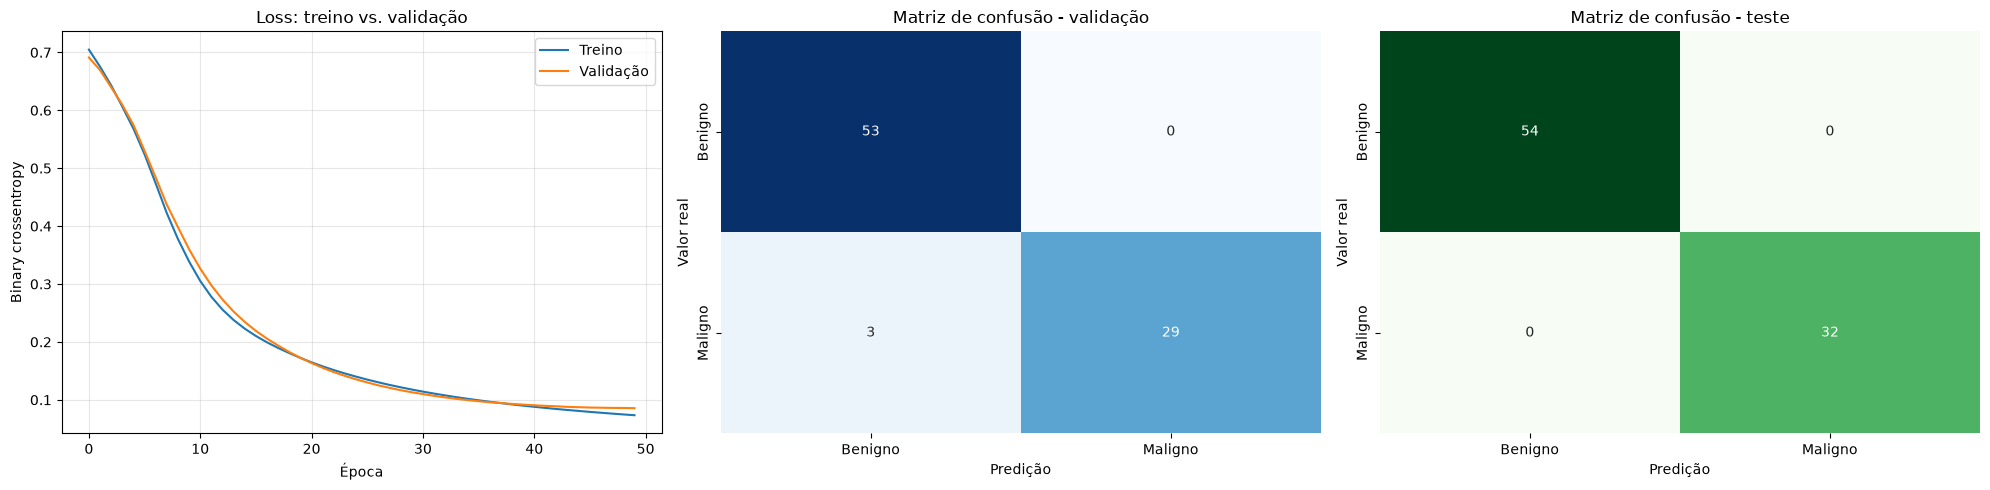

In [23]:
# Visualize training/validation loss and confusion matrices for both evaluation sets.
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

axes[0].plot(history.history["loss"], label="Treino")
axes[0].plot(history.history["val_loss"], label="Validação")
axes[0].set_title("Loss: treino vs. validação")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Binary crossentropy")
axes[0].legend()
axes[0].grid(alpha=0.3)

validation_confusion = confusion_matrix(
    y_val["diagnosis_target"],
    validation_predictions,
)
sns.heatmap(
    validation_confusion,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Benigno", "Maligno"],
    yticklabels=["Benigno", "Maligno"],
    ax=axes[1],
)
axes[1].set_title("Matriz de confusão - validação")
axes[1].set_xlabel("Predição")
axes[1].set_ylabel("Valor real")

test_confusion = confusion_matrix(
    y_test["diagnosis_target"],
    test_predictions,
)
sns.heatmap(
    test_confusion,
    annot=True,
    fmt="d",
    cmap="Greens",
    cbar=False,
    xticklabels=["Benigno", "Maligno"],
    yticklabels=["Benigno", "Maligno"],
    ax=axes[2],
)
axes[2].set_title("Matriz de confusão - teste")
axes[2].set_xlabel("Predição")
axes[2].set_ylabel("Valor real")

plt.tight_layout()
plt.show()

## Relatório Executivo

### Contexto de negócio

O modelo classifica tumores como benignos ou malignos a partir de características derivadas de exames de câncer de mama. A solução pode apoiar a triagem clínica, priorizando casos suspeitos para avaliação especializada e reduzindo o tempo de resposta, sem substituir a decisão médica.

### Justificativa da arquitetura

Foi utilizada uma MLP com entrada dimensionada pelo número de variáveis preditoras após o pré-processamento, duas camadas ocultas densas com 32 e 16 neurônios e ativação ReLU. Essa configuração permite o aprendizado de relações não lineares mantendo complexidade compatível com o tamanho do dataset. A camada de saída possui um neurônio com ativação Sigmoid, adequada à classificação binária. O treinamento utiliza Adam, `binary_crossentropy` e Early Stopping monitorando a perda de validação.

### Conclusão dos resultados

Na execução registrada com 50 épocas, o modelo alcançou acurácia de 96,47% no conjunto de validação, com 3 erros em 85 amostras. Para a classe maligna, a validação apresentou Precision de 1,00, Recall de 0,91 e F1-Score de 0,95. No conjunto de teste, o modelo obteve acurácia de 100%, ROC AUC de 1,00 e nenhum erro nas 86 amostras avaliadas.

Apesar dos resultados excelentes, a acurácia perfeita no teste deve ser interpretada com cautela devido ao tamanho reduzido do conjunto. O modelo é promissor para uma etapa de triagem, mas não deve ser colocado em produção sem validação externa, análise de estabilidade em diferentes subgrupos, acompanhamento de falsos negativos e aprovação clínica e regulatória.